In [1]:
import os
import random
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score,
    average_precision_score,
    hamming_loss
)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [2]:
dataset_path = "/kaggle/input/datasets/johnarevalo/mmimdb/multimodal_imdb.hdf5"

with h5py.File(dataset_path, "r") as f:
    X_image = f["vgg_features"][:]
    X_text = f["features"][:]
    y = f["genres"][:]

X_image_train = X_image[:15552]
X_image_val = X_image[15552:18160]
X_image_test = X_image[18160:]

X_text_train = X_text[:15552]
X_text_val = X_text[15552:18160]
X_text_test = X_text[18160:]

y_train = y[:15552]
y_val = y[15552:18160]
y_test = y[18160:]

print("Image features:", X_image.shape)
print("Text features:", X_text.shape)
print("Labels:", y.shape)

print("Training samples:", len(y_train))
print("Validation samples:", len(y_val))
print("Testing samples:", len(y_test))

Image features: (25959, 4096)
Text features: (25959, 300)
Labels: (25959, 23)
Training samples: 15552
Validation samples: 2608
Testing samples: 7799


In [3]:
print("Missing values in image features:", np.isnan(X_image).sum())
print("Missing values in text features:", np.isnan(X_text).sum())
print("Missing values in labels:", np.isnan(y).sum())

print("\nNumber of genres:", y.shape[1])
print("Average genres per movie:", round(y.sum(axis=1).mean(), 2))
print("Minimum genres per movie:", y.sum(axis=1).min())
print("Maximum genres per movie:", y.sum(axis=1).max())

genre_names = [
    "Drama", "Comedy", "Romance", "Thriller", "Crime",
    "Action", "Adventure", "Horror", "Documentary", "Mystery",
    "Sci-Fi", "Fantasy", "Family", "Biography", "War",
    "History", "Music", "Animation", "Musical", "Western",
    "Sport", "Short", "Film-Noir"
]

genre_counts = y_train.sum(axis=0)

genre_distribution = pd.DataFrame({
    "Genre": genre_names,
    "Training Samples": genre_counts.astype(int)
}).sort_values("Training Samples", ascending=False)

display(genre_distribution)

Missing values in image features: 0
Missing values in text features: 0
Missing values in labels: 0

Number of genres: 23
Average genres per movie: 2.48
Minimum genres per movie: 1
Maximum genres per movie: 10


,Genre,Training Samples
0,Drama,8424
1,Comedy,5108
2,Romance,3226
3,Thriller,3113
4,Crime,2293
5,Action,2155
6,Adventure,1611
7,Horror,1603
8,Documentary,1234
9,Mystery,1231


In [4]:
image_scaler = StandardScaler()
text_scaler = StandardScaler()

X_image_train_scaled = image_scaler.fit_transform(X_image_train)
X_image_val_scaled = image_scaler.transform(X_image_val)
X_image_test_scaled = image_scaler.transform(X_image_test)

X_text_train_scaled = text_scaler.fit_transform(X_text_train)
X_text_val_scaled = text_scaler.transform(X_text_val)
X_text_test_scaled = text_scaler.transform(X_text_test)

print("Image training:", X_image_train_scaled.shape)
print("Text training:", X_text_train_scaled.shape)
print("Preprocessing completed.")

Image training: (15552, 4096)
Text training: (15552, 300)
Preprocessing completed.


In [9]:
def train_model(model, X_train, y_train_data, X_val, y_val_data, epochs=10, weight_decay=0.0):
    model = model.to(device)

    train_dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train_data, dtype=torch.float32)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=256,
        shuffle=True
    )

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=weight_decay
    )

    train_losses = []
    val_losses = []

    X_val_tensor = torch.tensor(
        X_val, dtype=torch.float32
    ).to(device)

    y_val_tensor = torch.tensor(
        y_val_data, dtype=torch.float32
    ).to(device)

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for batch_X, batch_y in train_loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        train_losses.append(total_loss / len(train_loader))

        model.eval()
        with torch.no_grad():
            val_outputs = model(X_val_tensor)
            val_loss = criterion(
                val_outputs, y_val_tensor
            ).item()

        val_losses.append(val_loss)

        print(
            f"Epoch {epoch+1}/{epochs} "
            f"- Train Loss: {train_losses[-1]:.4f} "
            f"- Val Loss: {val_losses[-1]:.4f}"
        )

    return model, train_losses, val_losses

In [10]:
poster_model = nn.Sequential(
    nn.Linear(4096, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 23)
)

print(poster_model)

Sequential(
  (0): Linear(in_features=4096, out_features=512, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=512, out_features=23, bias=True)
)


In [11]:
poster_model, poster_train_losses, poster_val_losses = train_model(
    poster_model,
    X_image_train_scaled,
    y_train,
    X_image_val_scaled,
    y_val,
    epochs=10
)

Epoch 1/10 - Train Loss: 0.2989 - Val Loss: 0.2529
Epoch 2/10 - Train Loss: 0.2300 - Val Loss: 0.2547
Epoch 3/10 - Train Loss: 0.2084 - Val Loss: 0.2606
Epoch 4/10 - Train Loss: 0.1888 - Val Loss: 0.2698
Epoch 5/10 - Train Loss: 0.1705 - Val Loss: 0.2825
Epoch 6/10 - Train Loss: 0.1531 - Val Loss: 0.2971
Epoch 7/10 - Train Loss: 0.1356 - Val Loss: 0.3113
Epoch 8/10 - Train Loss: 0.1201 - Val Loss: 0.3290
Epoch 9/10 - Train Loss: 0.1069 - Val Loss: 0.3472
Epoch 10/10 - Train Loss: 0.0958 - Val Loss: 0.3662


In [12]:
text_model = nn.Sequential(
    nn.Linear(300, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 23)
)

print(text_model)

Sequential(
  (0): Linear(in_features=300, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=256, out_features=23, bias=True)
)


In [13]:
text_model, text_train_losses, text_val_losses = train_model(
    text_model,
    X_text_train_scaled,
    y_train,
    X_text_val_scaled,
    y_val,
    epochs=10
)

Epoch 1/10 - Train Loss: 0.3292 - Val Loss: 0.2303
Epoch 2/10 - Train Loss: 0.2190 - Val Loss: 0.2093
Epoch 3/10 - Train Loss: 0.2039 - Val Loss: 0.2020
Epoch 4/10 - Train Loss: 0.1960 - Val Loss: 0.1979
Epoch 5/10 - Train Loss: 0.1912 - Val Loss: 0.1961
Epoch 6/10 - Train Loss: 0.1874 - Val Loss: 0.1950
Epoch 7/10 - Train Loss: 0.1839 - Val Loss: 0.1945
Epoch 8/10 - Train Loss: 0.1817 - Val Loss: 0.1942
Epoch 9/10 - Train Loss: 0.1799 - Val Loss: 0.1939
Epoch 10/10 - Train Loss: 0.1772 - Val Loss: 0.1936


In [14]:
early_fusion_model = nn.Sequential(
    nn.Linear(4396, 512),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 23)
)

print(early_fusion_model)

Sequential(
  (0): Linear(in_features=4396, out_features=512, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.4, inplace=False)
  (3): Linear(in_features=512, out_features=256, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=256, out_features=23, bias=True)
)


In [15]:
X_early_train = np.concatenate(
    [X_image_train_scaled, X_text_train_scaled],
    axis=1
)

X_early_val = np.concatenate(
    [X_image_val_scaled, X_text_val_scaled],
    axis=1
)

print("Combined training features:", X_early_train.shape)
print("Combined validation features:", X_early_val.shape)

Combined training features: (15552, 4396)
Combined validation features: (2608, 4396)


In [16]:
early_fusion_model, early_train_losses, early_val_losses = train_model(
    early_fusion_model,
    X_early_train,
    y_train,
    X_early_val,
    y_val,
    epochs=10,
    weight_decay=0.0001
)

Epoch 1/10 - Train Loss: 0.2868 - Val Loss: 0.2144
Epoch 2/10 - Train Loss: 0.2078 - Val Loss: 0.1994
Epoch 3/10 - Train Loss: 0.1873 - Val Loss: 0.1971
Epoch 4/10 - Train Loss: 0.1742 - Val Loss: 0.1939
Epoch 5/10 - Train Loss: 0.1630 - Val Loss: 0.1958
Epoch 6/10 - Train Loss: 0.1539 - Val Loss: 0.1977
Epoch 7/10 - Train Loss: 0.1454 - Val Loss: 0.2000
Epoch 8/10 - Train Loss: 0.1391 - Val Loss: 0.2072
Epoch 9/10 - Train Loss: 0.1337 - Val Loss: 0.2081
Epoch 10/10 - Train Loss: 0.1283 - Val Loss: 0.2092


In [17]:
poster_model.eval()
text_model.eval()

with torch.no_grad():
    poster_val_predictions = torch.sigmoid(
        poster_model(
            torch.tensor(X_image_val_scaled, dtype=torch.float32).to(device)
        )
    ).cpu().numpy()

    text_val_predictions = torch.sigmoid(
        text_model(
            torch.tensor(X_text_val_scaled, dtype=torch.float32).to(device)
        )
    ).cpu().numpy()

print("Poster predictions:", poster_val_predictions.shape)
print("Text predictions:", text_val_predictions.shape)

Poster predictions: (2608, 23)
Text predictions: (2608, 23)


In [18]:
from sklearn.metrics import f1_score

best_score = 0
best_image_weight = 0
best_threshold = 0

for image_weight in np.arange(0, 1.01, 0.1):
    combined_predictions = (
        image_weight * poster_val_predictions
        + (1 - image_weight) * text_val_predictions
    )

    for threshold in np.arange(0.10, 0.601, 0.025):
        predicted_labels = (
            combined_predictions >= threshold
        ).astype(int)

        score = f1_score(
            y_val,
            predicted_labels,
            average="macro",
            zero_division=0
        )

        if score > best_score:
            best_score = score
            best_image_weight = image_weight
            best_threshold = threshold

print("Best image weight:", round(best_image_weight, 2))
print("Best text weight:", round(1 - best_image_weight, 2))
print("Best threshold:", round(best_threshold, 3))
print("Validation Macro-F1:", round(best_score, 4))

Best image weight: 0.2
Best text weight: 0.8
Best threshold: 0.225
Validation Macro-F1: 0.5337


In [19]:
poster_model.eval()
text_model.eval()
early_fusion_model.eval()

with torch.no_grad():
    poster_test_predictions = torch.sigmoid(
        poster_model(
            torch.tensor(X_image_test_scaled, dtype=torch.float32).to(device)
        )
    ).cpu().numpy()

    text_test_predictions = torch.sigmoid(
        text_model(
            torch.tensor(X_text_test_scaled, dtype=torch.float32).to(device)
        )
    ).cpu().numpy()

    early_test_predictions = torch.sigmoid(
        early_fusion_model(
            torch.tensor(
                np.concatenate(
                    [X_image_test_scaled, X_text_test_scaled],
                    axis=1
                ),
                dtype=torch.float32
            ).to(device)
        )
    ).cpu().numpy()

late_test_predictions = (
    best_image_weight * poster_test_predictions
    + (1 - best_image_weight) * text_test_predictions
)

print("Poster:", poster_test_predictions.shape)
print("Text:", text_test_predictions.shape)
print("Early fusion:", early_test_predictions.shape)
print("Late fusion:", late_test_predictions.shape)

Poster: (7799, 23)
Text: (7799, 23)
Early fusion: (7799, 23)
Late fusion: (7799, 23)


In [20]:
model_predictions = {
    "Poster-only": (poster_test_predictions, 0.5),
    "Text-only": (text_test_predictions, 0.5),
    "Early Fusion": (early_test_predictions, 0.5),
    "Late Fusion": (late_test_predictions, best_threshold)
}

results = []

for model_name, (predictions, threshold) in model_predictions.items():
    predicted_labels = (predictions >= threshold).astype(int)

    results.append({
        "Model": model_name,
        "Micro-F1": f1_score(y_test, predicted_labels, average="micro", zero_division=0),
        "Macro-F1": f1_score(y_test, predicted_labels, average="macro", zero_division=0),
        "Micro-AP": average_precision_score(y_test, predictions, average="micro"),
        "Macro-AP": average_precision_score(y_test, predictions, average="macro"),
        "Hamming Loss": hamming_loss(y_test, predicted_labels)
    })

results_df = pd.DataFrame(results).round(4)

display(results_df)

,Model,Micro-F1,Macro-F1,Micro-AP,Macro-AP,Hamming Loss
0,Poster-only,0.4037,0.2352,0.4181,0.2639,0.1064
1,Text-only,0.5771,0.4459,0.6598,0.5438,0.0769
2,Early Fusion,0.5745,0.4591,0.6312,0.5155,0.0816
3,Late Fusion,0.6255,0.5410,0.6728,0.5660,0.0964


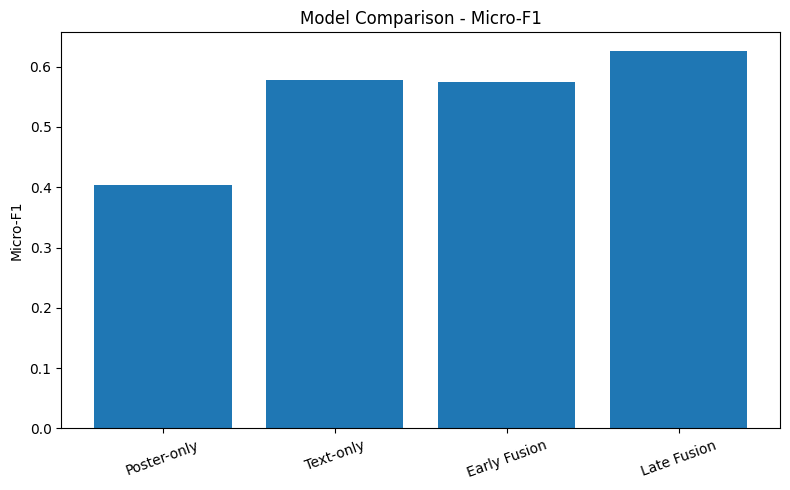

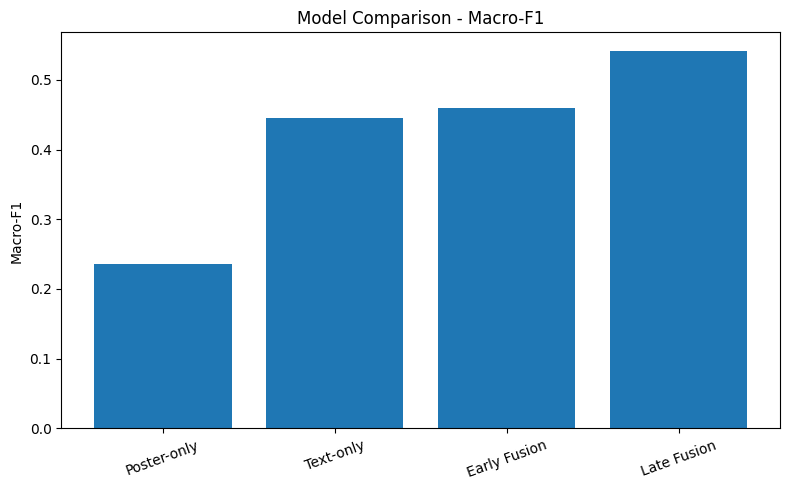

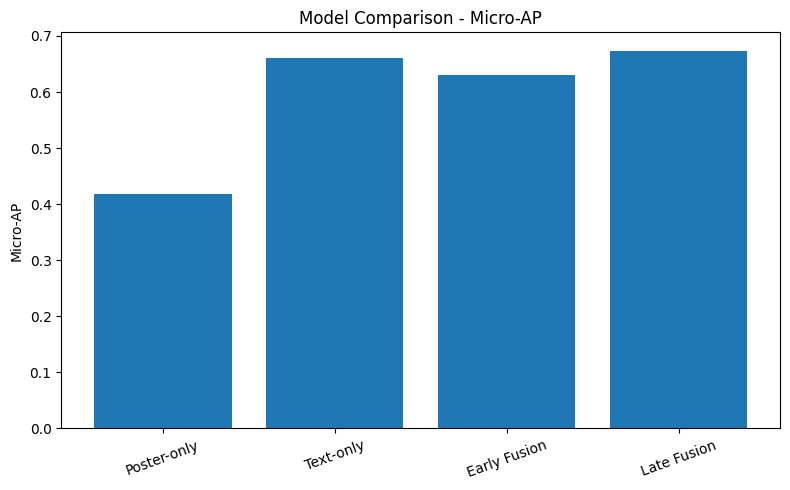

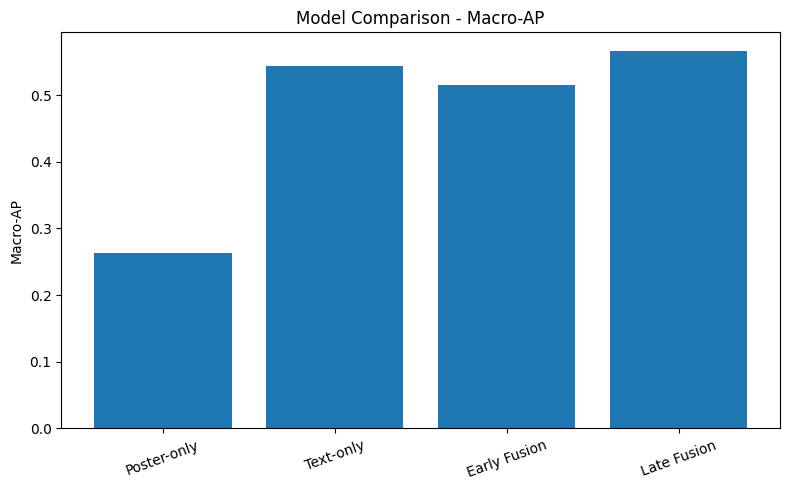

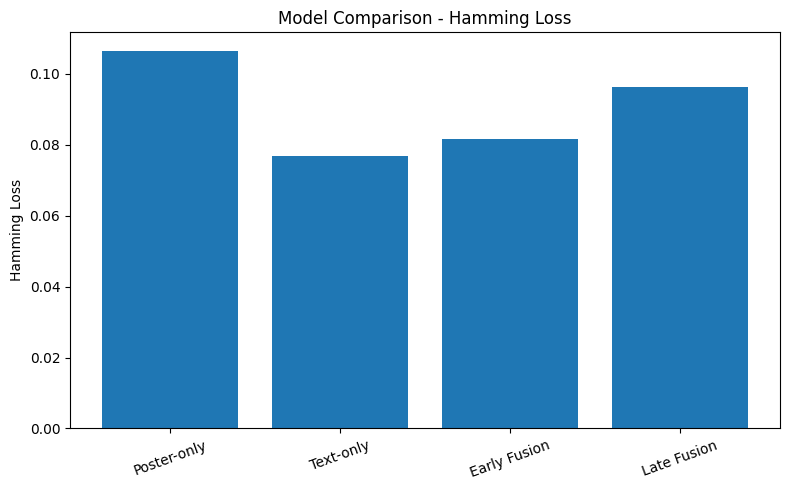

In [21]:
metrics = [
    "Micro-F1",
    "Macro-F1",
    "Micro-AP",
    "Macro-AP",
    "Hamming Loss"
]

for metric in metrics:
    plt.figure(figsize=(8, 5))
    plt.bar(results_df["Model"], results_df[metric])
    plt.title(f"Model Comparison - {metric}")
    plt.ylabel(metric)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(f"{metric.lower().replace('-', '_')}_comparison.png", dpi=300)
    plt.show()

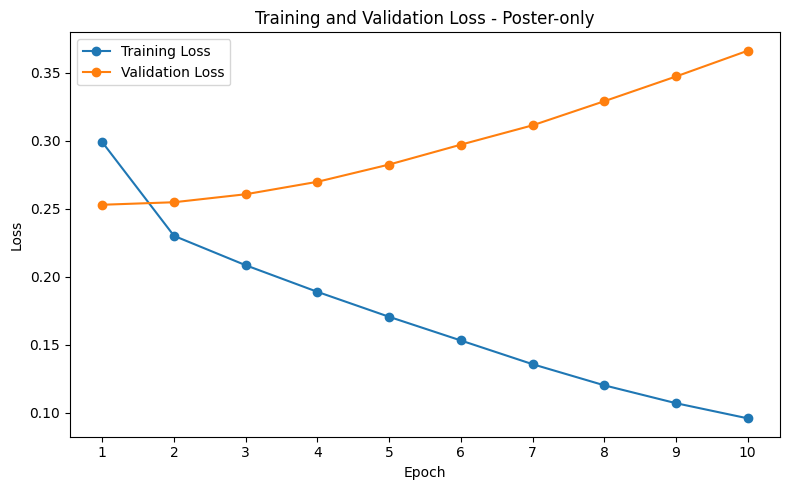

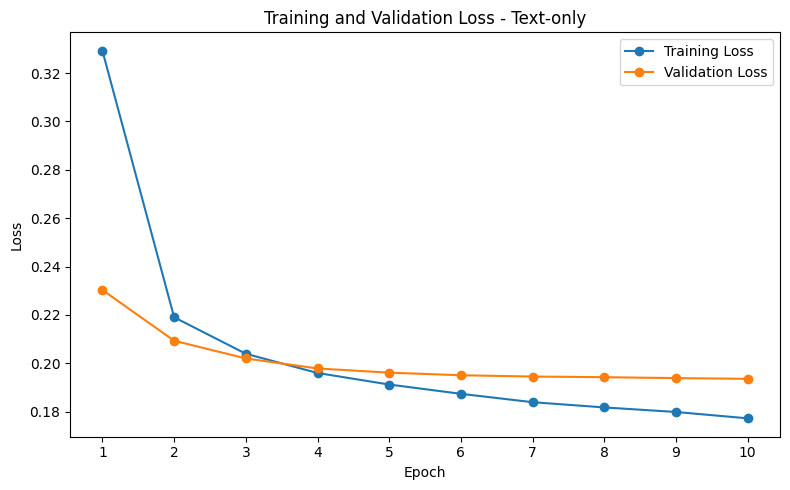

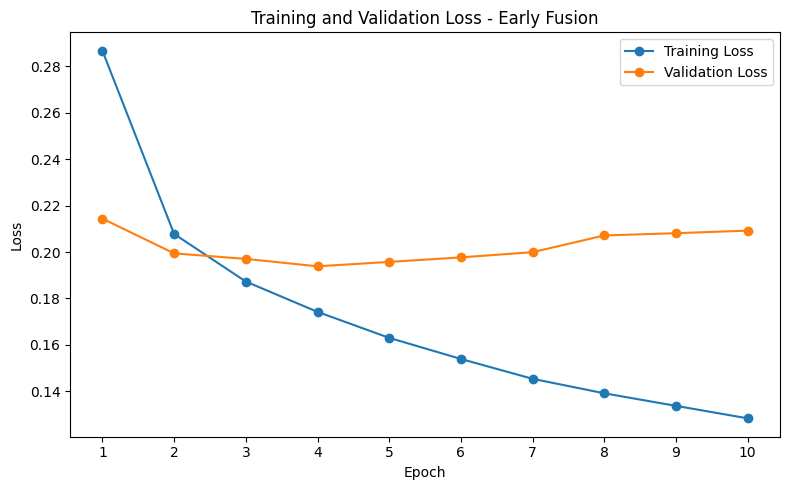

In [22]:
loss_curves = {
    "Poster-only": (poster_train_losses, poster_val_losses),
    "Text-only": (text_train_losses, text_val_losses),
    "Early Fusion": (early_train_losses, early_val_losses)
}

for model_name, (train_loss, val_loss) in loss_curves.items():
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, 11), train_loss, marker="o", label="Training Loss")
    plt.plot(range(1, 11), val_loss, marker="o", label="Validation Loss")
    plt.title(f"Training and Validation Loss - {model_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.xticks(range(1, 11))
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{model_name.lower().replace('-', '_').replace(' ', '_')}_loss.png", dpi=300)
    plt.show()

In [23]:
late_test_labels = (
    late_test_predictions >= best_threshold
).astype(int)

genre_results = pd.DataFrame({
    "Genre": genre_names,
    "Test Samples": y_test.sum(axis=0).astype(int),
    "F1 Score": [
        f1_score(
            y_test[:, i],
            late_test_labels[:, i],
            zero_division=0
        )
        for i in range(len(genre_names))
    ],
    "Average Precision": [
        average_precision_score(
            y_test[:, i],
            late_test_predictions[:, i]
        )
        for i in range(len(genre_names))
    ]
})

genre_results = genre_results.sort_values(
    "F1 Score",
    ascending=False
).round(4)

display(genre_results)

,Genre,Test Samples,F1 Score,Average Precision
8,Documentary,629,0.7417,0.7907
0,Drama,4142,0.7341,0.8165
20,Sport,191,0.6757,0.7073
7,Horror,825,0.6699,0.7383
10,Sci-Fi,586,0.6667,0.7129
1,Comedy,2611,0.6527,0.7437
19,Western,210,0.6453,0.7036
14,War,401,0.6361,0.6914
4,Crime,1163,0.6292,0.6628
3,Thriller,1567,0.6077,0.6142


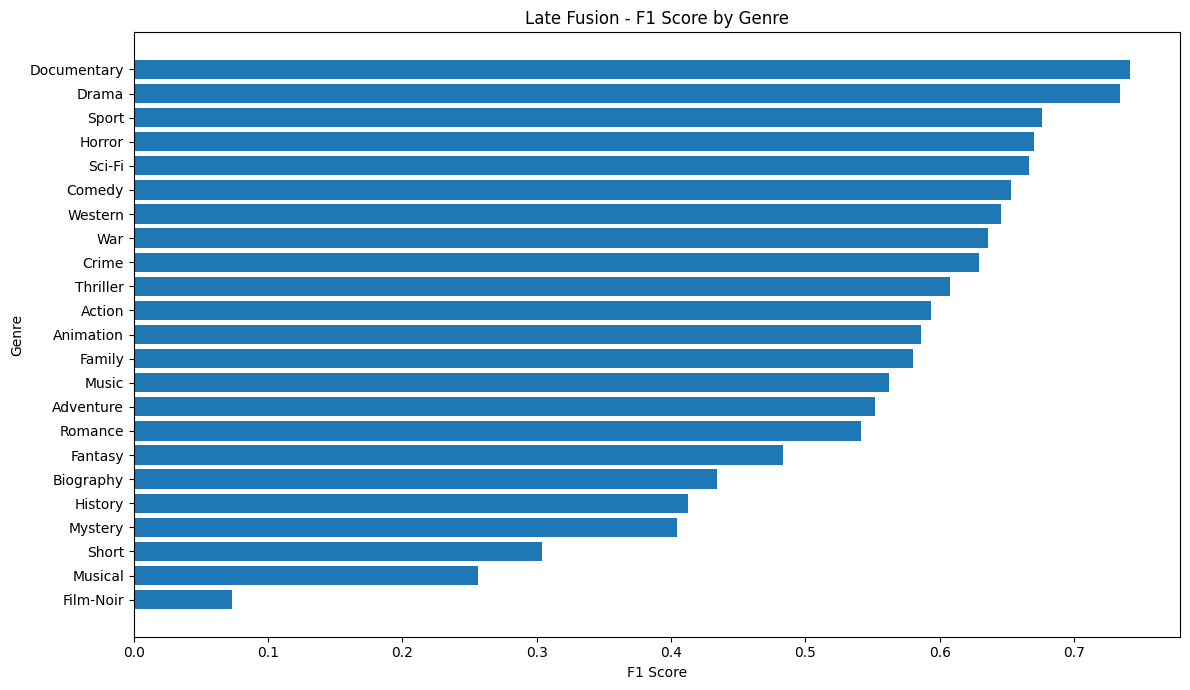

In [24]:
plt.figure(figsize=(12, 7))
plt.barh(genre_results["Genre"], genre_results["F1 Score"])
plt.xlabel("F1 Score")
plt.ylabel("Genre")
plt.title("Late Fusion - F1 Score by Genre")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("per_genre_f1.png", dpi=300)
plt.show()

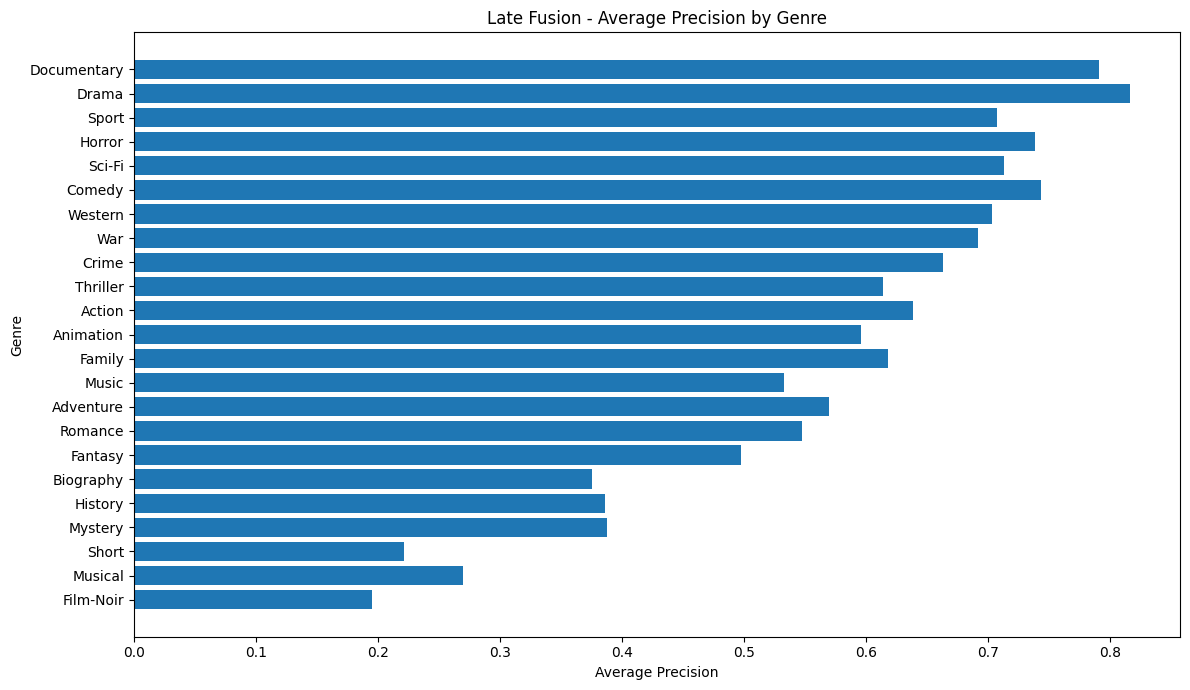

In [25]:
plt.figure(figsize=(12, 7))
plt.barh(
    genre_results["Genre"],
    genre_results["Average Precision"]
)
plt.xlabel("Average Precision")
plt.ylabel("Genre")
plt.title("Late Fusion - Average Precision by Genre")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("per_genre_average_precision.png", dpi=300)
plt.show()

In [26]:
results_df.to_csv("model_comparison_results.csv", index=False)

genre_results.to_csv("genre_performance_results.csv", index=False)

print("Results saved successfully.")

Results saved successfully.


In [27]:
torch.save(poster_model.state_dict(), "poster_model.pth")
torch.save(text_model.state_dict(), "text_model.pth")
torch.save(early_fusion_model.state_dict(), "early_fusion_model.pth")

print("All trained models saved successfully.")

All trained models saved successfully.


In [28]:
import joblib

joblib.dump(image_scaler, "image_scaler.pkl")
joblib.dump(text_scaler, "text_scaler.pkl")

np.savez(
    "late_fusion_settings.npz",
    image_weight=best_image_weight,
    text_weight=1 - best_image_weight,
    threshold=best_threshold
)

print("Preprocessing and late-fusion settings saved successfully.")

Preprocessing and late-fusion settings saved successfully.
